# Adult income — EDA

We want to predict whether a person's income is above 50K using the other census attributes.

One row is one person. There are 14 features and one target: `>50K` or `<=50K`.

Here we use only `adult.data`. The official test file is for final evaluation in the modeling notebook.

Source: [UCI Adult](https://archive.ics.uci.edu/dataset/2/adult).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

columns = ["age","workclass","fnlwgt","education","education-num","marital-status","occupation","relationship","race","sex","capital-gain","capital-loss","hours-per-week","native-country","income"]

raw = pd.read_csv("Adult Data/dataset/adult.data", names=columns,
                  header=None, skipinitialspace=True)
df = raw.replace("?", np.nan)

print("Rows and columns:", df.shape)
display(df.head(3))

Rows and columns: (32561, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K


## First look at the data

Which columns are numeric, which are categorical, and where do we have missing data?

In [2]:
summary = pd.DataFrame({
    "dtype": df.dtypes,
    "missing": df.isna().sum(),
    "missing %": df.isna().mean().mul(100).round(2),
    "unique values": df.nunique(),
})
display(summary)

,dtype,missing,missing %,unique values
age,int64,0,0.00,73
workclass,str,1836,5.64,8
fnlwgt,int64,0,0.00,21648
education,str,0,0.00,16
education-num,int64,0,0.00,16
marital-status,str,0,0.00,7
occupation,str,1843,5.66,14
relationship,str,0,0.00,6
race,str,0,0.00,5
sex,str,0,0.00,2


## Before looking at features, what is the income split?

This gives us the reference point for the comparisons below.

,people,percent
income,,
<=50K,24720,75.92
>50K,7841,24.08


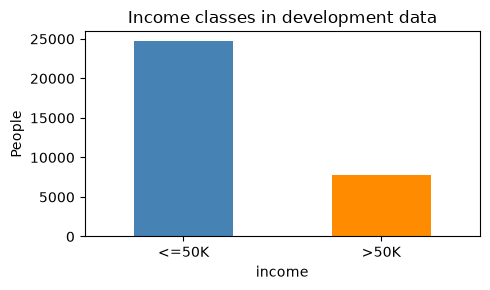

In [3]:
income_split = df["income"].value_counts().reindex(["<=50K", ">50K"])
display(pd.DataFrame({
    "people": income_split,
    "percent": (income_split / len(df) * 100).round(2),
}))
income_split.plot.bar(rot=0, color=["steelblue", "darkorange"], figsize=(5, 3))
plt.ylabel("People")
plt.title("Income classes in development data")
plt.tight_layout()
plt.show()

So always predicting <=50K already gives about 76% accuracy. We need to compare against this baseline and check how well we identify >50K too.

## Missing data — is a null check enough?

Let us check the original values before replacing anything.

In [4]:
display(pd.DataFrame({
    "nulls in raw file": raw.isna().sum(),
    "question marks": raw.eq("?").sum(),
}).loc[["workclass", "occupation", "native-country"]])

,nulls in raw file,question marks
workclass,0,1836
occupation,0,1843
native-country,0,583


The unknowns are written as `?`, so a normal null check misses them. We replaced these with NaN in `df`.

Now should we delete these rows, or keep the other information in them?

income,<=50K,>50K
Observed workclass,0.751,0.249
Missing workclass,0.896,0.104


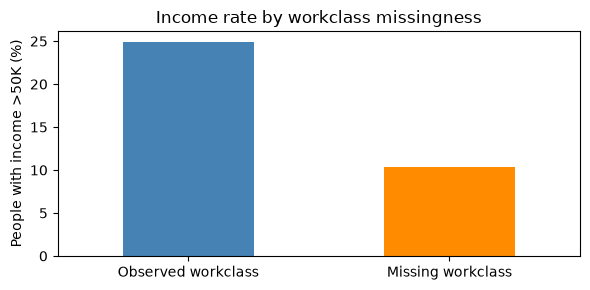

In [5]:
missing_workclass = df["workclass"].isna()
workclass_income = pd.crosstab(missing_workclass, df["income"], normalize="index")
workclass_income.index = ["Observed workclass", "Missing workclass"]
display(workclass_income.round(4))

workclass_income[">50K"].mul(100).plot.bar(
    rot=0, color=["steelblue", "darkorange"], figsize=(6, 3))
plt.ylabel("People with income >50K (%)")
plt.title("Income rate by workclass missingness")
plt.tight_layout()
plt.show()

The >50K proportion is lower when workclass is missing. But maybe the age mix is different in these two groups?

Let us check within age bands before deciding what this means.

In [6]:
check = df.assign(
    age_band=pd.cut(
        df["age"],
        bins=[0, 25, 40, 60, float("inf")],
        right=False,
        labels=["<25", "25–39", "40–59", "60+"],
    ),
    workclass_missing=df["workclass"].isna(),
    high_income=df["income"].eq(">50K"),
)

display(
    check.groupby(
        ["age_band", "workclass_missing"],
        observed=True,
    ).agg(
        count=("high_income", "size"),
        high_income_rate=("high_income", "mean"),
    )
)

count  high_income_rate
age_band workclass_missing                         
<25      False               4938          0.011948
         True                 632          0.003165
25–39    False              12381          0.220418
         True                 373          0.080429
40–59    False              11286          0.381535
         True                 307          0.205212
60+      False               2120          0.262264
         True                 524          0.183206

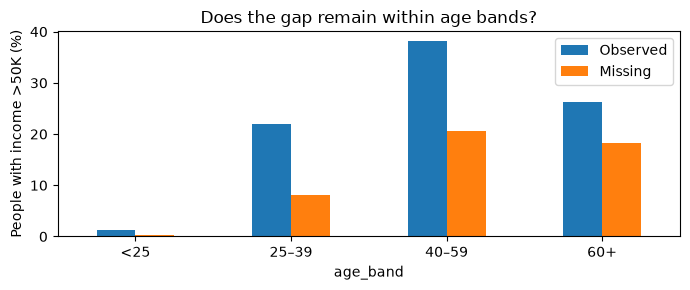

In [7]:
age_check = check.groupby(["age_band", "workclass_missing"], observed=True)["high_income"].mean().unstack()
age_check.columns = ["Observed", "Missing"]
age_check.mul(100).plot.bar(rot=0, figsize=(7, 3))
plt.ylabel("People with income >50K (%)")
plt.title("Does the gap remain within age bands?")
plt.tight_layout()
plt.show()

The gap remains in these age bands. So age alone does not explain what we see here.

This is an association. It does not tell us why workclass is missing, or prove that missingness causes lower income.

### Are the missing values happening together?

In [8]:
display(pd.crosstab(
    df["workclass"].isna(), df["occupation"].isna(),
    rownames=["Workclass missing"], colnames=["Occupation missing"],
))
display(df.loc[df["workclass"].eq("Never-worked"),
               ["workclass", "occupation"]])

Occupation missing,False,True
Workclass missing,,
False,30718,7
True,0,1836


,workclass,occupation
5361,Never-worked,NaN
10845,Never-worked,NaN
14772,Never-worked,NaN
20337,Never-worked,NaN
23232,Never-worked,NaN
32304,Never-worked,NaN
32314,Never-worked,NaN


All 1,836 rows with missing workclass also have missing occupation. The other 7 missing occupations belong to people explicitly marked Never-worked.

But missing workclass and Never-worked are different things. We should not merge them just because their income patterns look similar.

**Next experiment:** keep unknown workclass as a separate category and compare it with merging into Never-worked. Modeling will show that comparison.

## EDA analysis for categorical variables

### Education — are these two columns giving us different information?

Let us first look at their values.

In [9]:
display(df[["education", "education-num"]].drop_duplicates()
        .sort_values("education-num").reset_index(drop=True))

,education,education-num
0,Preschool,1
1,1st-4th,2
2,5th-6th,3
3,7th-8th,4
4,9th,5
5,10th,6
6,11th,7
7,12th,8
8,HS-grad,9
9,Some-college,10


It looks like each education category has one number. Let us check both directions.

In [10]:
display(df.groupby("education")["education-num"].agg(["min", "max", "nunique"]))

,min,max,nunique
education,,,
10th,6,6,1
11th,7,7,1
12th,8,8,1
1st-4th,2,2,1
5th-6th,3,3,1
7th-8th,4,4,1
9th,5,5,1
Assoc-acdm,12,12,1
Assoc-voc,11,11,1


In [11]:
print("One number per education:",
      df.groupby("education")["education-num"].nunique().eq(1).all())
print("One education per number:",
      df.groupby("education-num")["education"].nunique().eq(1).all())

One number per education: True
One education per number: True


So they have a 1:1 mapping in this data.

But the representation still matters. For logistic regression, numeric education assumes the same change in log-odds from 9 to 10 as from 13 to 14. One-hot education can learn separate effects.

The main modeling flow keeps education-num and drops education. That avoids duplicate information, but we should be clear about this assumption.

## Numeric features — what does correlation tell us?

Let us start with Pearson correlation. This checks linear association; it is not a test for every possible relationship.

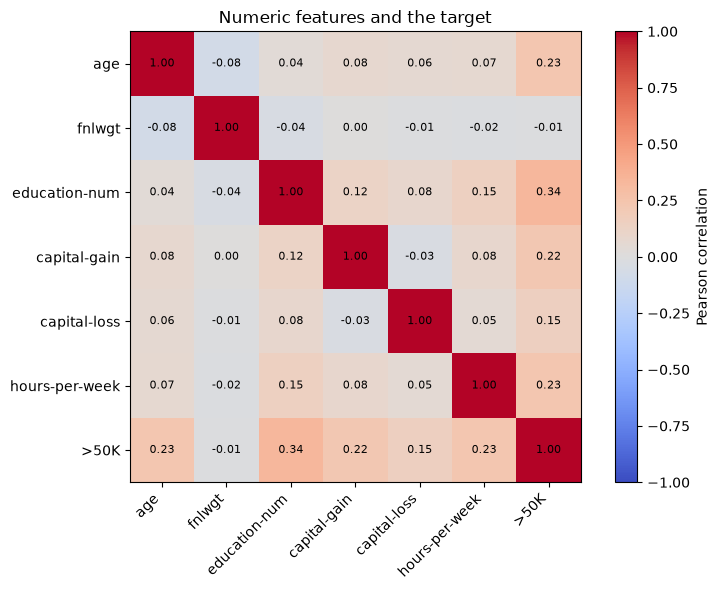

In [12]:
numeric = df.select_dtypes(include="number").copy()
numeric[">50K"] = df["income"].eq(">50K").astype(int)
corr = numeric.corr()

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="Pearson correlation")
ax.set_title("Numeric features and the target")
plt.tight_layout()
plt.show()

A small correlation does not mean a feature is useless. Also, categorical relationships are not covered by this numeric matrix.

Age is a useful check: does its relationship with income really look like a straight line?

,people,high_income_rate
age_band,,
"[15, 25)",5570,0.0110
"[25, 35)",8479,0.1683
"[35, 45)",8151,0.3316
"[45, 55)",5853,0.4012
"[55, 65)",3172,0.3235
"[65, 75)",1050,0.2181
"[75, 91)",286,0.1643


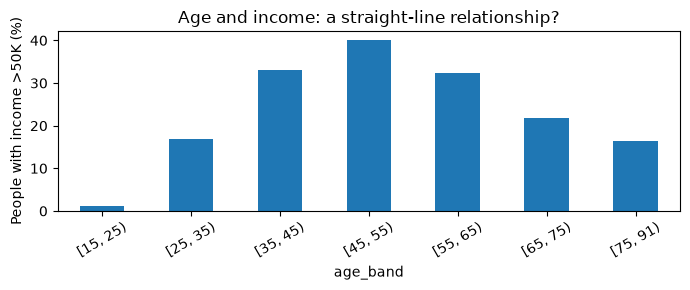

In [13]:
age_data = df.assign(
    age_band=pd.cut(df["age"], bins=[15, 25, 35, 45, 55, 65, 75, 91], right=False),
    high_income=df["income"].eq(">50K"),
)
age_rates = age_data.groupby("age_band", observed=True).agg(
    people=("high_income", "size"),
    high_income_rate=("high_income", "mean"),
)
display(age_rates.round(4))
age_rates["high_income_rate"].mul(100).plot.bar(rot=30, figsize=(7, 3))
plt.ylabel("People with income >50K (%)")
plt.title("Age and income: a straight-line relationship?")
plt.tight_layout()
plt.show()

The rate rises and then falls. A single correlation number does not show that shape.

Scaling age only changes its origin and units. It does not let raw-age logistic regression rise and then fall when other features are fixed.

**Modeling idea:** compare a linear baseline with models that can learn nonlinear relationships. This plot is marginal, so it does not prove the conditional relationship has the same shape.

## Capital gain and loss — zeros, skewness, and large values

Are these zeros unknown values? A zero is a recorded amount, whereas `?` means unknown. We keep that distinction.

In [14]:
capital = df[["capital-gain", "capital-loss"]]
capital_summary = capital.describe().T[["min", "50%", "75%", "max"]]
capital_summary["zero %"] = capital.eq(0).mean().mul(100)
capital_summary["skewness"] = capital.skew()
display(capital_summary.round(2))

,min,50%,75%,max,zero %,skewness
capital-gain,0.0,0.0,0.0,99999.0,91.67,11.95
capital-loss,0.0,0.0,0.0,4356.0,95.33,4.59


Most values are zero, and a small number are very large. Let us look at the raw distribution and then zoom in on positive amounts using log1p.

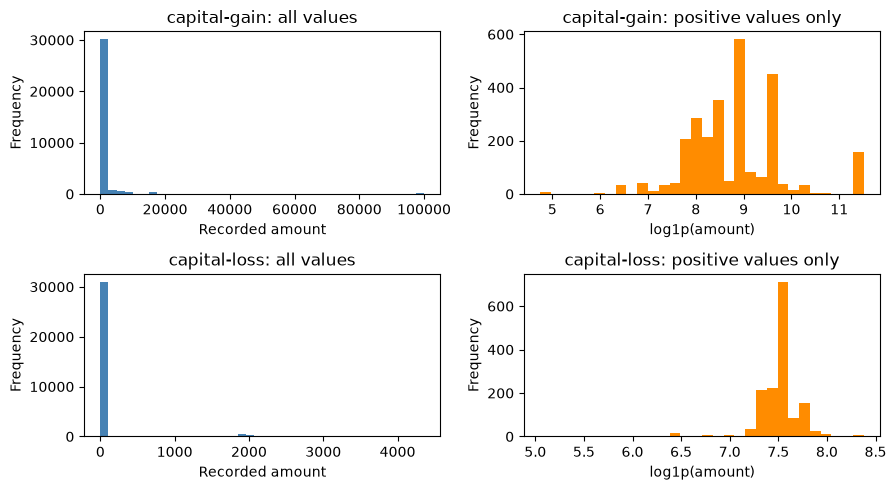

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(9, 5))
for i, column in enumerate(capital.columns):
    capital[column].plot.hist(bins=40, ax=axes[i, 0], color="steelblue")
    axes[i, 0].set_title(f"{column}: all values")
    axes[i, 0].set_xlabel("Recorded amount")
    np.log1p(capital.loc[capital[column] > 0, column]).plot.hist(
        bins=30, ax=axes[i, 1], color="darkorange")
    axes[i, 1].set_title(f"{column}: positive values only")
    axes[i, 1].set_xlabel("log1p(amount)")
plt.tight_layout()
plt.show()

The right plots exclude zeros only to see the positive values clearly. We are not deleting those rows from training.

Standardization does not remove skewness. Large values alone are not enough reason to remove records either.

**Next experiment:** raw vs log1p capital features for logistic regression, with the same folds and model settings. A clearer plot does not guarantee a better model.

## A few checks before calling these values noise

Let us check the ranges and repeated rows. These are checks to investigate, not automatic reasons to delete data.

In [16]:
display(df[["age", "education-num", "hours-per-week",
            "capital-gain", "capital-loss"]].agg(["min", "max"]))
print("Repeated full rows:", df.duplicated().sum())

Repeated full rows: 24


,age,education-num,hours-per-week,capital-gain,capital-loss
min,17,1,1,0,0
max,90,16,99,99999,4356


Age includes 17-year-olds. So we should not describe the data as containing no minors.

Repeated feature values do not prove two records are the same person. We have no person ID here. The baseline below retains the supplied records.

## What about fnlwgt?

This is a survey weight: roughly how many people a sampled record represents after adjustment.

Using it as a feature, weighting training, and weighting evaluation are three different choices. Our initial baseline below keeps all 14 features. The main modeling notebook drops fnlwgt as a predictor and reports unweighted metrics.

## What this leads to in modeling

| Observation | Decision or experiment |
| --- | --- |
| Unknown categories are written as ? | Parse them explicitly and keep the other information in those rows |
| Unknown workclass is different from Never-worked | Compare separate Missing vs merged categories |
| The classes are about 76:24 | Start with a dummy baseline; report more than accuracy |
| Education and education-num map 1:1 | Avoid claiming they are independent information; explain the encoding assumption |
| Age shows a rise and fall | Compare linear and nonlinear models |
| Capital features have many zeros and a long tail | Compare raw vs log capital for LR; keep zeros as observed values |

These are observations and hypotheses. The modeling experiments decide whether a change helps prediction.

### What did not settle the question?

- A null check alone missed the question marks.
- Age differences alone did not explain the workclass-missing gap in these bands.
- A small Pearson correlation was not enough to rule out a useful relationship.
- Seeing skewness was not enough to claim that a log transform would improve the model.

The missing-category and log-capital results belong in the modeling notebook. We should report their actual CV changes, including changes that did not help.

## Initial baseline — bridge to modeling

This is the baseline from my original notebook: all 14 predictors, Unknown for missing categorical values, and logistic regression.

It keeps fnlwgt and both education columns. So it is not a controlled comparison with the main modeling pipeline, which drops those columns.

The preprocessing is inside the pipeline. Each fold learns its scaler, imputer, and encoder from its training rows.

In [17]:
label_map = {"<=50K": 0, ">50K": 1}

y = df["income"].map(label_map)

assert y.notna().all(), "Unexpected or missing income labels"
y = y.astype(int)

X = df.drop(columns=["income"]).copy()

print("Predictors:", X.shape)
print("Target:", y.shape)
print("Positive-class proportion:", y.mean())

Predictors: (32561, 14)
Target: (32561,)
Positive-class proportion: 0.2408095574460244


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

print("Numeric:", numeric_features)
print("Categorical:", categorical_features)

assert not X[numeric_features].isna().any().any(), \
    "Numeric missing values found: inspect before proceeding"

categorical_pipeline = Pipeline([
    ("impute", SimpleImputer(
        strategy="constant",
        fill_value="Unknown",
    )),
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

baseline = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(C=1.0, max_iter=2000)),
])

baseline

Numeric: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
Out[18]: 
Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['age', 'fnlwgt',
                                                   'education-num',
                                                   'capital-gain',
                                                   'capital-loss',
                                                   'hours-per-week']),
                                                 ('categorical',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(fill_value='Unknown',
                                                                               

In [19]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0,
)

folds = list(cv.split(X, y))

In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

models = {
    "Dummy": DummyClassifier(strategy="prior"),
    "Logistic regression": baseline,
}

scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "accuracy": "accuracy",
}

cv_results = {}
rows = []

for name, model in models.items():
    print(f"Evaluating {name}...")

    result = cross_validate(
        model,
        X,
        y,
        cv=folds,
        scoring=scoring,
        return_train_score=True,
        error_score="raise",
        n_jobs=2,
    )
    cv_results[name] = result

    for metric in scoring:
        rows.append({
            "model": name,
            "metric": metric,
            "train_mean": result[f"train_{metric}"].mean(),
            "validation_mean": result[f"test_{metric}"].mean(),
            "validation_std": result[f"test_{metric}"].std(),
        })

display(pd.DataFrame(rows).round(4))

Evaluating Dummy...
Evaluating Logistic regression...


,model,metric,train_mean,validation_mean,validation_std
0,Dummy,roc_auc,0.5000,0.5000,0.0000
1,Dummy,average_precision,0.2408,0.2408,0.0000
2,Dummy,accuracy,0.7592,0.7592,0.0000
3,Logistic regression,roc_auc,0.9089,0.9070,0.0037
4,Logistic regression,average_precision,0.7712,0.7676,0.0095
5,Logistic regression,accuracy,0.8532,0.8522,0.0029


In [21]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report

oof_pred = cross_val_predict(
    baseline,
    X,
    y,
    cv=folds,
    method="predict",
    n_jobs=2,
)

display(pd.DataFrame(
    confusion_matrix(y, oof_pred, labels=[0, 1]),
    index=["Actual <=50K", "Actual >50K"],
    columns=["Predicted <=50K", "Predicted >50K"],
))

print(classification_report(
    y,
    oof_pred,
    target_names=["<=50K", ">50K"],
    zero_division=0,
))

              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91     24720
        >50K       0.74      0.60      0.66      7841

    accuracy                           0.85     32561
   macro avg       0.81      0.77      0.78     32561
weighted avg       0.85      0.85      0.85     32561



,Predicted <=50K,Predicted >50K
Actual <=50K,23025,1695
Actual >50K,3118,4723


The dummy gives us the starting point. Logistic regression improves on it, but the confusion matrix shows that >50K recall still needs attention at its default threshold.

Changing the threshold trades false positives against false negatives; it does not improve the ranking itself.

Ashish will cover model comparisons, the preprocessing experiments, threshold choice, and final evaluation. Our EDA gave us the questions to test.

## Limits

This is historical census data. Associations here do not establish causes, modern population performance, or purchasing behaviour. Small groups need care, and a good overall score can still hide uneven errors.